# BIFlow — ETL & KPI pour les demandes NYC 311




## 1. Préparer l’environnement et charger le fichier

Le fichier d’entrée est un extrait de 5 000 à 10 000 lignes du jeu officiel NYC 311. Cette première cellule vérifie sa présence et indique précisément comment l’obtenir si nécessaire. Dans le portail NYC Open Data, ouvrir le jeu « 311 Service Requests from 2020 to Present », choisir Exporter → CSV et enregistrer un extrait dans `data/raw/nyc311_sample_jun_oct_2026.csv` (prioritaire), avec `data/raw/nyc311_sample_jun_oct_2026.csv` (prioritaire), avec `data/raw/nyc311_sample_jun_oct_2026.csv` (prioritaire), avec `data/raw/nyc311_sample_jun_oct_2026.csv` (prioritaire), avec `data/raw/nyc311_sample_jun_oct_2026.csv` (prioritaire), avec `data/raw/nyc311_sample_jun_oct_2026.csv` (prioritaire), avec `data/raw/nyc311_sample.csv` en repli en repli en repli en repli en repli en repli. Ne téléchargez qu’un échantillon pour ce prototype. Un export complet peut contenir plusieurs millions de lignes.

In [2]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 80)
pd.set_option("display.max_colwidth", 100)
plt.style.use("seaborn-v0_8-whitegrid")

PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                      if any((p / rel).exists() for rel in ["data/raw/nyc311_sample_jun_oct_2026.csv", "data/raw/nyc311_sample.csv"])), None)
if PROJECT_ROOT is None:
    PROJECT_ROOT = Path.cwd().parent if Path.cwd().name.lower() == "notebooks" else Path.cwd()
DATA_CANDIDATES = [PROJECT_ROOT / "data/raw/nyc311_sample_jun_oct_2026.csv",
                   PROJECT_ROOT / "data/raw/nyc311_sample.csv"]
DATA_PATH = next((path for path in DATA_CANDIDATES if path.exists()), DATA_CANDIDATES[0])
SAMPLE_METADATA_PATH = PROJECT_ROOT / "data/raw/nyc311_sample_metadata.json"
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"CSV absent : {DATA_PATH}. Téléchargez un extrait CSV depuis "
        "https://data.cityofnewyork.us/Social-Services/311-Service-Requests-from-2020-to-Present/erm2-nwe9 "
        "placez un extrait de 5 000 à 10 000 lignes dans data/raw/nyc311_sample_jun_oct_2026.csv (ou data/raw/nyc311_sample.csv)."
    )
df_raw = pd.read_csv(DATA_PATH, low_memory=False)
df_raw_snapshot = df_raw.copy(deep=True)
raw_hash_before = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
print(f"Fichier sélectionné : {DATA_PATH} | {len(df_raw):,} lignes × {len(df_raw.columns):,} colonnes")
assert 5_000 <= len(df_raw) <= 10_000, "L’échantillon attendu comporte de 5 000 à 10 000 lignes."
df_raw.head()

Fichier : d:\Analyst_Agent\data\raw\nyc311_sample.csv | 8,000 lignes × 44 colonnes


,unique_key,created_date,closed_date,agency,agency_name,complaint_type,descriptor,descriptor_2,location_type,incident_zip,incident_address,street_name,cross_street_1,cross_street_2,intersection_street_1,intersection_street_2,address_type,city,landmark,facility_type,status,due_date,resolution_description,resolution_action_updated_date,community_board,council_district,police_precinct,bbl,borough,x_coordinate_state_plane,y_coordinate_state_plane,open_data_channel_type,park_facility_name,park_borough,vehicle_type,taxi_company_borough,taxi_pick_up_location,bridge_highway_name,bridge_highway_direction,road_ramp,bridge_highway_segment,latitude,longitude,location
0,70753723,2026-10-15T02:06:16.000,NaN,NYPD,New York City Police Department,Noise - Residential,Loud Music/Party,NaN,Residential Building/House,10466.0,4305 CARPENTER AVENUE,CARPENTER AVENUE,EAST 236 STREET,EAST 237 STREET,EAST 236 STREET,EAST 237 STREET,ADDRESS,BRONX,CARPENTER AVENUE,NaN,In Progress,NaN,NaN,NaN,12 BRONX,11.0,Precinct 47,2.050340e+09,BRONX,1023248.0,265989.0,PHONE,Unspecified,BRONX,NaN,NaN,NaN,NaN,NaN,NaN,NaN,40.896666,-73.858939,POINT (-73.858939397044 40.896665887093)
1,70761541,2026-10-15T02:05:57.000,NaN,NYPD,New York City Police Department,Noise - Residential,Banging/Pounding,NaN,Residential Building/House,11221.0,910 DEKALB AVENUE,DEKALB AVENUE,MARCUS GARVEY BOULEVARD,LEWIS AVENUE,MARCUS GARVEY BOULEVARD,LEWIS AVENUE,ADDRESS,BROOKLYN,DEKALB AVENUE,NaN,In Progress,NaN,NaN,NaN,03 BROOKLYN,36.0,Precinct 81,3.016010e+09,BROOKLYN,1001040.0,191664.0,PHONE,Unspecified,BROOKLYN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,40.692734,-73.939454,POINT (-73.939454264451 40.692734251505)
2,70758525,2026-10-15T02:05:24.000,NaN,NYPD,New York City Police Department,Blocked Driveway,Partial Access,NaN,Street/Sidewalk,11239.0,646 SCHROEDERS AVENUE,SCHROEDERS AVENUE,BERRIMAN STREET,SCHROEDERS WALK,BERRIMAN STREET,SCHROEDERS WALK,ADDRESS,BROOKLYN,SCHROEDERS AVENUE,NaN,In Progress,NaN,NaN,NaN,05 BROOKLYN,42.0,Precinct 75,3.045861e+09,BROOKLYN,1020567.0,178501.0,ONLINE,Unspecified,BROOKLYN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,40.656546,-73.869110,POINT (-73.869109747107 40.656546231579)
3,70756133,2026-10-15T02:05:23.000,NaN,NYPD,New York City Police Department,Noise - Residential,Loud Television,NaN,Residential Building/House,11106.0,34-35 12 STREET,12 STREET,34 AVENUE,35 AVENUE,34 AVENUE,35 AVENUE,ADDRESS,ASTORIA,12 STREET,NaN,In Progress,NaN,NaN,NaN,01 QUEENS,26.0,Precinct 114,4.005230e+09,QUEENS,1001534.0,217348.0,PHONE,Unspecified,QUEENS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,40.763230,-73.937607,POINT (-73.937606902491 40.763229595164)
4,70760045,2026-10-15T02:03:59.000,NaN,NYPD,New York City Police Department,Noise - Street/Sidewalk,Loud Music/Party,NaN,Street/Sidewalk,11201.0,153 BRIDGE PARK DRIVE,BRIDGE PARK DRIVE,BEND,JORALEMON STREET,BEND,JORALEMON STREET,ADDRESS,BROOKLYN,BRIDGE PARK DRIVE,NaN,In Progress,NaN,NaN,NaN,02 BROOKLYN,33.0,Precinct 84,3.002458e+09,BROOKLYN,984016.0,192077.0,MOBILE,Unspecified,BROOKLYN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,40.693884,-74.000844,POINT (-74.000843832356 40.693883764345)


## 2. Profilage initial (avant nettoyage)

Le profilage décrit les données telles qu’elles sont livrées. Il permet de confronter le schéma réel aux champs attendus et de voir les manques avant toute transformation. Une colonne facultative absente n’est pas créée artificiellement.

In [3]:
print("Dimensions :", df_raw.shape)
display(df_raw.head(5))
print("Colonnes :", df_raw.columns.tolist())
display(df_raw.dtypes.rename("dtype initial").to_frame())

expected = ["unique_key", "created_date", "closed_date", "complaint_type", "borough", "agency", "status"]
missing_expected = [c for c in expected if c not in df_raw.columns]
print("Champs attendus absents (status est facultatif) :", missing_expected)
assert "created_date" in df_raw.columns, "Le champ created_date est requis pour les analyses temporelles."

Dimensions : (8000, 44)


,unique_key,created_date,closed_date,agency,agency_name,complaint_type,descriptor,descriptor_2,location_type,incident_zip,incident_address,street_name,cross_street_1,cross_street_2,intersection_street_1,intersection_street_2,address_type,city,landmark,facility_type,status,due_date,resolution_description,resolution_action_updated_date,community_board,council_district,police_precinct,bbl,borough,x_coordinate_state_plane,y_coordinate_state_plane,open_data_channel_type,park_facility_name,park_borough,vehicle_type,taxi_company_borough,taxi_pick_up_location,bridge_highway_name,bridge_highway_direction,road_ramp,bridge_highway_segment,latitude,longitude,location
0,70753723,2026-10-15T02:06:16.000,NaN,NYPD,New York City Police Department,Noise - Residential,Loud Music/Party,NaN,Residential Building/House,10466.0,4305 CARPENTER AVENUE,CARPENTER AVENUE,EAST 236 STREET,EAST 237 STREET,EAST 236 STREET,EAST 237 STREET,ADDRESS,BRONX,CARPENTER AVENUE,NaN,In Progress,NaN,NaN,NaN,12 BRONX,11.0,Precinct 47,2.050340e+09,BRONX,1023248.0,265989.0,PHONE,Unspecified,BRONX,NaN,NaN,NaN,NaN,NaN,NaN,NaN,40.896666,-73.858939,POINT (-73.858939397044 40.896665887093)
1,70761541,2026-10-15T02:05:57.000,NaN,NYPD,New York City Police Department,Noise - Residential,Banging/Pounding,NaN,Residential Building/House,11221.0,910 DEKALB AVENUE,DEKALB AVENUE,MARCUS GARVEY BOULEVARD,LEWIS AVENUE,MARCUS GARVEY BOULEVARD,LEWIS AVENUE,ADDRESS,BROOKLYN,DEKALB AVENUE,NaN,In Progress,NaN,NaN,NaN,03 BROOKLYN,36.0,Precinct 81,3.016010e+09,BROOKLYN,1001040.0,191664.0,PHONE,Unspecified,BROOKLYN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,40.692734,-73.939454,POINT (-73.939454264451 40.692734251505)
2,70758525,2026-10-15T02:05:24.000,NaN,NYPD,New York City Police Department,Blocked Driveway,Partial Access,NaN,Street/Sidewalk,11239.0,646 SCHROEDERS AVENUE,SCHROEDERS AVENUE,BERRIMAN STREET,SCHROEDERS WALK,BERRIMAN STREET,SCHROEDERS WALK,ADDRESS,BROOKLYN,SCHROEDERS AVENUE,NaN,In Progress,NaN,NaN,NaN,05 BROOKLYN,42.0,Precinct 75,3.045861e+09,BROOKLYN,1020567.0,178501.0,ONLINE,Unspecified,BROOKLYN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,40.656546,-73.869110,POINT (-73.869109747107 40.656546231579)
3,70756133,2026-10-15T02:05:23.000,NaN,NYPD,New York City Police Department,Noise - Residential,Loud Television,NaN,Residential Building/House,11106.0,34-35 12 STREET,12 STREET,34 AVENUE,35 AVENUE,34 AVENUE,35 AVENUE,ADDRESS,ASTORIA,12 STREET,NaN,In Progress,NaN,NaN,NaN,01 QUEENS,26.0,Precinct 114,4.005230e+09,QUEENS,1001534.0,217348.0,PHONE,Unspecified,QUEENS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,40.763230,-73.937607,POINT (-73.937606902491 40.763229595164)
4,70760045,2026-10-15T02:03:59.000,NaN,NYPD,New York City Police Department,Noise - Street/Sidewalk,Loud Music/Party,NaN,Street/Sidewalk,11201.0,153 BRIDGE PARK DRIVE,BRIDGE PARK DRIVE,BEND,JORALEMON STREET,BEND,JORALEMON STREET,ADDRESS,BROOKLYN,BRIDGE PARK DRIVE,NaN,In Progress,NaN,NaN,NaN,02 BROOKLYN,33.0,Precinct 84,3.002458e+09,BROOKLYN,984016.0,192077.0,MOBILE,Unspecified,BROOKLYN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,40.693884,-74.000844,POINT (-74.000843832356 40.693883764345)


Colonnes : ['unique_key', 'created_date', 'closed_date', 'agency', 'agency_name', 'complaint_type', 'descriptor', 'descriptor_2', 'location_type', 'incident_zip', 'incident_address', 'street_name', 'cross_street_1', 'cross_street_2', 'intersection_street_1', 'intersection_street_2', 'address_type', 'city', 'landmark', 'facility_type', 'status', 'due_date', 'resolution_description', 'resolution_action_updated_date', 'community_board', 'council_district', 'police_precinct', 'bbl', 'borough', 'x_coordinate_state_plane', 'y_coordinate_state_plane', 'open_data_channel_type', 'park_facility_name', 'park_borough', 'vehicle_type', 'taxi_company_borough', 'taxi_pick_up_location', 'bridge_highway_name', 'bridge_highway_direction', 'road_ramp', 'bridge_highway_segment', 'latitude', 'longitude', 'location']


,dtype initial
unique_key,int64
created_date,str
closed_date,str
agency,str
agency_name,str
complaint_type,str
descriptor,str
descriptor_2,str
location_type,str
incident_zip,float64


Champs attendus absents (status est facultatif) : []


In [4]:
missing_initial = pd.DataFrame({
    "missing_count": df_raw.isna().sum(),
    "missing_percent": (df_raw.isna().mean() * 100).round(2),
}).sort_values("missing_percent", ascending=False)
display(missing_initial)

for col in [c for c in ["complaint_type", "borough", "agency", "status"] if c in df_raw.columns]:
    print(f"\n{col} — {df_raw[col].nunique(dropna=True)} valeurs distinctes")
    display(df_raw[col].value_counts(dropna=False).head(12).rename("count").to_frame())
display(df_raw.describe(include="all").T.head(25))

,missing_count,missing_percent
facility_type,7995,99.94
taxi_company_borough,7990,99.88
due_date,7977,99.71
road_ramp,7973,99.66
bridge_highway_direction,7968,99.60
bridge_highway_name,7948,99.35
bridge_highway_segment,7948,99.35
taxi_pick_up_location,7921,99.01
vehicle_type,7562,94.52
descriptor_2,5121,64.01



complaint_type — 130 valeurs distinctes


,count
complaint_type,
Illegal Parking,1263
Noise - Residential,637
Noise - Street/Sidewalk,435
UNSANITARY CONDITION,411
Blocked Driveway,391
Street Condition,220
PLUMBING,200
PAINT/PLASTER,196
Noise,185



borough — 6 valeurs distinctes


,count
borough,
BROOKLYN,2625
QUEENS,1794
BRONX,1675
MANHATTAN,1583
STATEN ISLAND,312
Unspecified,11



agency — 13 valeurs distinctes


,count
agency,
NYPD,3438
HPD,1720
DOT,641
DSNY,561
DEP,481
DPR,331
DOB,244
DOHMH,227
DHS,194



status — 5 valeurs distinctes


,count
status,
Closed,3374
In Progress,2407
Open,2197
Assigned,21
Pending,1


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
unique_key,8000.0,NaN,NaN,NaN,70756490.517,3499.927661,70750397.0,70753415.25,70756449.5,70759477.25,70762495.0
created_date,8000,6529,2026-10-14T15:37:50.000,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
closed_date,3619,2362,2026-10-14T20:54:50.000,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
agency,8000,13,NYPD,3438,NaN,NaN,NaN,NaN,NaN,NaN,NaN
agency_name,8000,13,New York City Police Department,3438,NaN,NaN,NaN,NaN,NaN,NaN,NaN
complaint_type,8000,130,Illegal Parking,1263,NaN,NaN,NaN,NaN,NaN,NaN,NaN
descriptor,7854,427,Loud Music/Party,637,NaN,NaN,NaN,NaN,NaN,NaN,NaN
descriptor_2,2879,296,BROKEN OR MISSING,129,NaN,NaN,NaN,NaN,NaN,NaN,NaN
location_type,7296,74,Street/Sidewalk,2691,NaN,NaN,NaN,NaN,NaN,NaN,NaN
incident_zip,7923.0,NaN,NaN,NaN,10822.93298,533.546595,10000.0,10452.0,11203.0,11233.0,11694.0


## 3. ETL — copie de travail et standardisation

`df_raw` conserve les valeurs importées, sans modification. Les noms de champs sont normalisés en minuscules avec underscores ; un dictionnaire conserve la correspondance avec le nom source. Les dates non interprétables deviennent manquantes et sont comptabilisées. Les espaces périphériques des chaînes sont retirés ; les chaînes vides deviennent manquantes. Les catégories métier ne sont pas renommées.

In [5]:
df = df_raw.copy(deep=True)
source_column_map = {str(c): str(c).strip().lower().replace(" ", "_") for c in df.columns}
df = df.rename(columns=source_column_map)
if not df.columns.is_unique:
    raise ValueError("La normalisation a créé des noms de colonnes dupliqués ; vérifier le schéma source.")

text_cols = df.select_dtypes(include=["object", "string"]).columns
for col in text_cols:
    df[col] = df[col].astype("string").str.strip().replace("", pd.NA)

date_parse_report = {}
for col in [c for c in ["created_date", "closed_date"] if c in df.columns]:
    original_nonmissing = df[col].notna().sum()
    parsed = pd.to_datetime(df[col], errors="coerce", utc=True)
    date_parse_report[col] = {"nonmissing_before": int(original_nonmissing),
                              "invalid_after_parse": int(original_nonmissing - parsed.notna().sum())}
    df[col] = parsed
print("Correspondance colonnes source → standardisées :", source_column_map)
print("Dates invalides/non interprétables :", date_parse_report)
display(df.dtypes.to_frame("dtype après standardisation"))

Correspondance colonnes source → standardisées : {'unique_key': 'unique_key', 'created_date': 'created_date', 'closed_date': 'closed_date', 'agency': 'agency', 'agency_name': 'agency_name', 'complaint_type': 'complaint_type', 'descriptor': 'descriptor', 'descriptor_2': 'descriptor_2', 'location_type': 'location_type', 'incident_zip': 'incident_zip', 'incident_address': 'incident_address', 'street_name': 'street_name', 'cross_street_1': 'cross_street_1', 'cross_street_2': 'cross_street_2', 'intersection_street_1': 'intersection_street_1', 'intersection_street_2': 'intersection_street_2', 'address_type': 'address_type', 'city': 'city', 'landmark': 'landmark', 'facility_type': 'facility_type', 'status': 'status', 'due_date': 'due_date', 'resolution_description': 'resolution_description', 'resolution_action_updated_date': 'resolution_action_updated_date', 'community_board': 'community_board', 'council_district': 'council_district', 'police_precinct': 'police_precinct', 'bbl': 'bbl', 'borou

,dtype après standardisation
unique_key,int64
created_date,"datetime64[us, UTC]"
closed_date,"datetime64[us, UTC]"
agency,string
agency_name,string
complaint_type,string
descriptor,string
descriptor_2,string
location_type,string
incident_zip,float64


## 4. Doublons et règles de conservation

Un doublon exact répète toutes les valeurs d’une ligne. Un doublon d’identifiant partage `unique_key` mais peut contenir des informations différentes. On retire les répétitions exactes, qui n’ajoutent aucune information ; pour un identifiant répété, on ne retire que les lignes supplémentaires après conservation de la première occurrence, en signalant cette règle et le nombre concerné. Confirmer avec le métier si les mises à jour d’une même demande sont des événements distincts dans l’extrait.

In [6]:
rows_before_dedup = len(df)
exact_duplicate_mask = df.duplicated(keep="first")
exact_duplicates = int(exact_duplicate_mask.sum())
df = df.loc[~exact_duplicate_mask].copy()

id_duplicate_rows = 0
if "unique_key" in df.columns:
    valid_id = df["unique_key"].notna()
    id_duplicate_rows = int(df.loc[valid_id].duplicated(subset=["unique_key"], keep="first").sum())
    # Règle prototype : un enregistrement par clé ; conserver la première occurrence de l’extrait.
    df = pd.concat([
        df.loc[valid_id].drop_duplicates(subset=["unique_key"], keep="first"),
        df.loc[~valid_id]
    ]).sort_index().copy()
rows_after_dedup = len(df)
duplicates_removed = rows_before_dedup - rows_after_dedup
print({"rows_before_dedup": rows_before_dedup, "exact_duplicates": exact_duplicates,
       "repeated_id_rows": id_duplicate_rows, "total_rows_removed": duplicates_removed,
       "rows_after_dedup": rows_after_dedup})
assert rows_after_dedup == rows_before_dedup - duplicates_removed

{'rows_before_dedup': 8000, 'exact_duplicates': 0, 'repeated_id_rows': 0, 'total_rows_removed': 0, 'rows_after_dedup': 8000}


## 5. Qualité, valeurs manquantes et cohérence temporelle

Les valeurs manquantes sont d’abord rapportées ; aucune imputation n’est faite. Une absence de date de fermeture peut correspondre à une demande toujours en cours. Les dates de fermeture antérieures à la création sont signalées, sans correction automatique. Les durées négatives ou supérieures à dix ans sont signalées comme suspectes à examiner : le seuil est un repère de contrôle de ce prototype, pas une règle métier. Les durées suspectes restent dans les données brutes nettoyées, mais sont exclues des KPI de délai.

In [7]:
def missing_report(frame):
    return pd.DataFrame({"missing_count": frame.isna().sum(),
                         "missing_percent": (frame.isna().mean() * 100).round(2)})

missing_before_treatment = missing_report(df)
if "unique_key" in df.columns:
    missing_ids = int(df["unique_key"].isna().sum())
else:
    missing_ids = None
missing_categories = {c: int(df[c].isna().sum()) for c in ["complaint_type", "borough"] if c in df.columns}

if "created_date" in df.columns:
    temporal_conflict = df["closed_date"].notna() & df["created_date"].notna() & (df["closed_date"] < df["created_date"]) if "closed_date" in df.columns else pd.Series(False, index=df.index)
    df["temporal_inconsistency"] = temporal_conflict
else:
    df["temporal_inconsistency"] = False
temporal_inconsistency_count = int(df["temporal_inconsistency"].sum())

if "closed_date" in df.columns:
    df["resolution_days"] = (df["closed_date"] - df["created_date"]).dt.total_seconds() / 86400
    suspicious_duration = df["resolution_days"].lt(0) | df["resolution_days"].gt(3650)
    df["duration_suspicious"] = suspicious_duration.fillna(False)
    df.loc[df["temporal_inconsistency"] | df["duration_suspicious"], "resolution_days"] = np.nan
else:
    df["resolution_days"] = np.nan
    df["duration_suspicious"] = False

df["created_month"] = df["created_date"].dt.to_period("M").astype("string")
df["created_year"] = df["created_date"].dt.year.astype("Int64")
missing_after_treatment = missing_report(df)
print("Identifiants manquants :", missing_ids)
print("Catégories/arrondissements manquants :", missing_categories)
print("Incohérences fermeture < création :", temporal_inconsistency_count)
print("Durées suspectes exclues des KPI :", int(df["duration_suspicious"].sum()))
print("Valeurs manquantes avant traitement")
display(missing_before_treatment)
print("Valeurs manquantes après traitement (les absences légitimes sont conservées)")
display(missing_after_treatment)

Identifiants manquants : 0
Catégories/arrondissements manquants : {'complaint_type': 0, 'borough': 0}
Incohérences fermeture < création : 10
Durées suspectes exclues des KPI : 10
Valeurs manquantes avant traitement


C:\Users\HP\AppData\Local\Temp\ipykernel_7688\2978988884.py:28: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df["created_month"] = df["created_date"].dt.to_period("M").astype("string")


,missing_count,missing_percent
unique_key,0,0.00
created_date,0,0.00
closed_date,4381,54.76
agency,0,0.00
agency_name,0,0.00
complaint_type,0,0.00
descriptor,146,1.82
descriptor_2,5121,64.01
location_type,704,8.80
incident_zip,77,0.96


Valeurs manquantes après traitement (les absences légitimes sont conservées)


,missing_count,missing_percent
unique_key,0,0.00
created_date,0,0.00
closed_date,4381,54.76
agency,0,0.00
agency_name,0,0.00
complaint_type,0,0.00
descriptor,146,1.82
descriptor_2,5121,64.01
location_type,704,8.80
incident_zip,77,0.96


## 6. Jeu préparé et bilan ETL

`df_clean` est le jeu transformé ; le CSV source reste inchangé. Le bilan expose le compte de lignes avant/après et les anomalies qui restent à examiner. Les champs ajoutés décrivent la préparation et ne remplacent aucune valeur source.

In [8]:
df_clean = df.copy()
rows_initial = len(df_raw)
rows_final = len(df_clean)
important_missing = {c: int(df_clean[c].isna().sum()) for c in
                     ["unique_key", "created_date", "closed_date", "complaint_type", "borough"] if c in df_clean.columns}
etl_summary = pd.DataFrame([
    ("Lignes initiales", rows_initial), ("Doublons exacts détectés", exact_duplicates),
    ("Lignes répétant une clé détectées", id_duplicate_rows),
    ("Lignes supprimées au total", duplicates_removed), ("Lignes finales", rows_final),
    ("Incohérences temporelles", temporal_inconsistency_count),
    ("Durées suspectes exclues des KPI", int(df_clean["duration_suspicious"].sum()))
], columns=["metric", "value"])
display(etl_summary)
print("Manquants importants :", important_missing)
print("Transformations : standardisation noms/espaces, dates parsées, répétitions supprimées, variables temporelles.")
print("À valider : règle de dédoublonnage par clé, seuil de durée suspecte, traitement métier des demandes non clôturées.")
assert rows_final == rows_initial - duplicates_removed
assert not ((df_clean["resolution_days"] < 0).fillna(False)).any()
pd.testing.assert_frame_equal(df_raw, df_raw_snapshot)
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == raw_hash_before, "Le CSV brut a été modifié."
print("Contrôles locaux : compte de lignes cohérent, df_raw intact, aucune durée négative dans le KPI, CSV brut inchangé.")

,metric,value
0,Lignes initiales,8000
1,Doublons exacts détectés,0
2,Lignes répétant une clé détectées,0
3,Lignes supprimées au total,0
4,Lignes finales,8000
5,Incohérences temporelles,10
6,Durées suspectes exclues des KPI,10


Manquants importants : {'unique_key': 0, 'created_date': 0, 'closed_date': 4381, 'complaint_type': 0, 'borough': 0}
Transformations : standardisation noms/espaces, dates parsées, répétitions supprimées, variables temporelles.
À valider : règle de dédoublonnage par clé, seuil de durée suspecte, traitement métier des demandes non clôturées.
Contrôles locaux : compte de lignes cohérent, df_raw intact, aucune durée négative dans le KPI, CSV brut inchangé.


In [9]:
processed_dir = PROJECT_ROOT / "data/processed"
processed_dir.mkdir(parents=True, exist_ok=True)
clean_path = processed_dir / "nyc311_clean.csv"
df_clean.to_csv(clean_path, index=False)
assert len(pd.read_csv(clean_path, low_memory=False)) == len(df_clean)
print(f"Export nettoyé : {clean_path} ({clean_path.stat().st_size:,} octets)")

Export nettoyé : d:\Analyst_Agent\data\processed\nyc311_clean.csv (6,257,516 octets)


## 7. KPI — définitions, populations et calculs

Les comptes par dimension utilisent une ligne par clé conservée au nettoyage ; si aucune clé fiable n’est disponible, le repli est le nombre de lignes préparées. Le taux de fermeture utilise comme cohorte les demandes à date de création valide et comme numérateur celles de cette cohorte ayant une date de fermeture valide. Son niveau dépend de la période couverte et de la date d’extraction : les demandes récentes ont eu moins de temps pour être fermées. Aucun statut n’est interprété implicitement.

In [10]:
if "unique_key" in df_clean.columns and df_clean["unique_key"].notna().any():
    volume_total = int(df_clean["unique_key"].nunique(dropna=True) + df_clean["unique_key"].isna().sum())
    count_method = "clés unique_key distinctes + lignes sans clé"
else:
    volume_total = int(len(df_clean))
    count_method = "nombre de lignes préparées (clé absente/non exploitable)"

valid_resolution = df_clean["resolution_days"].dropna()
avg_resolution = float(valid_resolution.mean()) if len(valid_resolution) else np.nan
median_resolution = float(valid_resolution.median()) if len(valid_resolution) else np.nan
if "created_date" in df_clean and "closed_date" in df_clean:
    closure_cohort = df_clean["created_date"].notna()
    closure_denominator = int(closure_cohort.sum())
    closure_numerator = int((closure_cohort & df_clean["closed_date"].notna()).sum())
    closure_rate = closure_numerator / closure_denominator * 100 if closure_denominator else np.nan
else:
    closure_denominator = closure_numerator = 0
    closure_rate = np.nan

kpi_values = [
    ("request_volume", volume_total, "demandes", f"{count_method}; population df_clean"),
    ("mean_resolution_days", avg_resolution, "jours calendaires", f"moyenne sur {len(valid_resolution)} durées valides"),
    ("median_resolution_days", median_resolution, "jours calendaires", f"médiane sur {len(valid_resolution)} durées valides"),
    ("closure_rate", closure_rate, "%", f"{closure_numerator} fermées / {closure_denominator} créations datées"),
]
kpi_summary = pd.DataFrame(kpi_values, columns=["kpi_name", "value", "unit", "population_or_denominator"])
display(kpi_summary)
print("La moyenne est sensible aux durées extrêmes ; la médiane décrit le point central et résiste davantage aux longues queues.")
assert closure_denominator == int(df_clean["created_date"].notna().sum()) if "created_date" in df_clean else closure_denominator == 0

,kpi_name,value,unit,population_or_denominator
0,request_volume,8000.000000,demandes,clés unique_key distinctes + lignes sans clé; population df_clean
1,mean_resolution_days,0.068061,jours calendaires,moyenne sur 3609 durées valides
2,median_resolution_days,0.038194,jours calendaires,médiane sur 3609 durées valides
3,closure_rate,45.237500,%,3619 fermées / 8000 créations datées


La moyenne est sensible aux durées extrêmes ; la médiane décrit le point central et résiste davantage aux longues queues.


## 8. KPI par dimension et évolution

Les tableaux indiquent les volumes par catégorie disponible. Les valeurs de catégorie manquantes sont exclues de ces groupes, donc leurs sommes sont comparées au sous-ensemble non manquant. Pour les délais par catégorie, on fournit également la taille valide ; les petits groupes doivent être interprétés avec prudence.

In [11]:
def volume_by(column):
    if column not in df_clean.columns:
        print(f"KPI non calculé : colonne {column!r} absente du fichier.")
        return None
    return (df_clean.loc[df_clean[column].notna()].groupby(column, dropna=True)
            .size().rename("request_count").sort_values(ascending=False).reset_index())

kpi_by_complaint_type = volume_by("complaint_type")
kpi_by_borough = volume_by("borough")
kpi_by_agency = volume_by("agency")
for name, table, col in [("complaint_type", kpi_by_complaint_type, "complaint_type"),
                         ("borough", kpi_by_borough, "borough"), ("agency", kpi_by_agency, "agency")]:
    if table is not None:
        display(table.head(20))
        assert int(table["request_count"].sum()) == int(df_clean[col].notna().sum())

kpi_monthly = None
if df_clean["created_month"].notna().any():
    kpi_monthly = (df_clean.dropna(subset=["created_month"]).groupby("created_month")
                   .size().rename("request_count").reset_index())
    display(kpi_monthly.head())
else:
    print("Évolution mensuelle non calculable : aucune date de création valide.")

if "complaint_type" in df_clean.columns:
    kpi_resolution_by_type = (df_clean.dropna(subset=["complaint_type", "resolution_days"])
        .groupby("complaint_type")["resolution_days"].agg(median_days="median", sample_size="size")
        .sort_values("sample_size", ascending=False).reset_index())
    display(kpi_resolution_by_type.head(20))
else:
    kpi_resolution_by_type = None
    print("Délai par type non calculable : complaint_type absent.")
if "borough" in df_clean.columns:
    kpi_resolution_by_borough = (df_clean.dropna(subset=["borough", "resolution_days"])
        .groupby("borough")["resolution_days"].agg(median_days="median", sample_size="size")
        .sort_values("sample_size", ascending=False).reset_index())
    display(kpi_resolution_by_borough)
else:
    kpi_resolution_by_borough = None
    print("Délai par arrondissement non calculable : borough absent.")

,complaint_type,request_count
0,Illegal Parking,1263
1,Noise - Residential,637
2,Noise - Street/Sidewalk,435
3,UNSANITARY CONDITION,411
4,Blocked Driveway,391
5,Street Condition,220
6,PLUMBING,200
7,PAINT/PLASTER,196
8,Noise,185
9,DOOR/WINDOW,169


,borough,request_count
0,BROOKLYN,2625
1,QUEENS,1794
2,BRONX,1675
3,MANHATTAN,1583
4,STATEN ISLAND,312
5,Unspecified,11


,agency,request_count
0,NYPD,3438
1,HPD,1720
2,DOT,641
3,DSNY,561
4,DEP,481
5,DPR,331
6,DOB,244
7,DOHMH,227
8,DHS,194
9,TLC,81


,created_month,request_count
0,2026-10,8000


,complaint_type,median_days,sample_size
0,Illegal Parking,0.046319,1084
1,Noise - Residential,0.036667,523
2,Noise - Street/Sidewalk,0.031991,380
3,Blocked Driveway,0.048275,338
4,Abandoned Vehicle,0.065509,147
5,Noise - Vehicle,0.033634,128
6,General Construction/Plumbing,0.000000,105
7,Noise - Commercial,0.031748,84
8,Encampment,0.064184,82
9,Vendor Enforcement,0.014792,67


,borough,median_days,sample_size
0,BROOKLYN,0.036742,1254
1,QUEENS,0.037743,822
2,MANHATTAN,0.032870,753
3,BRONX,0.045255,647
4,STATEN ISLAND,0.054514,132
5,Unspecified,0.059722,1


## 9. Catalogue sémantique réutilisable

Ce catalogue documente les règles de calcul explicitement, afin qu’un futur composant BIFlow puisse réutiliser les définitions sans demander à un modèle de langage de calculer les valeurs.

In [12]:
kpi_catalog = pd.DataFrame([
    {"kpi_name":"request_volume", "business_definition":"Volume de demandes dans l’échantillon préparé", "formula":"nunique(unique_key) + lignes sans clé ; sinon nombre de lignes", "unit":"demandes", "filters":"df_clean après dédoublonnage", "limitations":"Portée et qualité des identifiants dépendent de l’export."},
    {"kpi_name":"mean_resolution_days", "business_definition":"Délai calendaire moyen de fermeture", "formula":"mean(resolution_days non manquant)", "unit":"jours", "filters":"Dates valides, cohérentes ; durées > 10 ans exclues comme suspectes", "limitations":"Sensible aux longues durées ; ne porte que sur demandes fermées calculables."},
    {"kpi_name":"median_resolution_days", "business_definition":"Délai calendaire médian de fermeture", "formula":"median(resolution_days non manquant)", "unit":"jours", "filters":"Même population que le délai moyen", "limitations":"Décrit le centre, sans résumer la queue longue."},
    {"kpi_name":"closure_rate", "business_definition":"Part des demandes de la cohorte datée ayant une fermeture datée", "formula":"100 × fermetures datées parmi créations datées / créations datées", "unit":"pour cent", "filters":"created_date valide ; closed_date valide au numérateur", "limitations":"Dépend de la fenêtre d’extraction et du temps d’observation ; statut non utilisé."},
    {"kpi_name":"monthly_request_volume", "business_definition":"Demandes selon leur mois de création", "formula":"count par période created_month", "unit":"demandes/mois", "filters":"created_date interprétable", "limitations":"Mois partiel et extrait non exhaustif possibles."},
    {"kpi_name":"median_resolution_by_group", "business_definition":"Médiane du délai parmi demandes fermées valides par catégorie", "formula":"median(resolution_days) groupé par catégorie ; afficher sample_size", "unit":"jours", "filters":"Catégorie et durée non manquantes", "limitations":"Comparer avec prudence les groupes de petite taille."},
])
display(kpi_catalog)

,kpi_name,business_definition,formula,unit,filters,limitations
0,request_volume,Volume de demandes dans l’échantillon préparé,nunique(unique_key) + lignes sans clé ; sinon nombre de lignes,demandes,df_clean après dédoublonnage,Portée et qualité des identifiants dépendent de l’export.
1,mean_resolution_days,Délai calendaire moyen de fermeture,mean(resolution_days non manquant),jours,"Dates valides, cohérentes ; durées > 10 ans exclues comme suspectes",Sensible aux longues durées ; ne porte que sur demandes fermées calculables.
2,median_resolution_days,Délai calendaire médian de fermeture,median(resolution_days non manquant),jours,Même population que le délai moyen,"Décrit le centre, sans résumer la queue longue."
3,closure_rate,Part des demandes de la cohorte datée ayant une fermeture datée,100 × fermetures datées parmi créations datées / créations datées,pour cent,created_date valide ; closed_date valide au numérateur,Dépend de la fenêtre d’extraction et du temps d’observation ; statut non utilisé.
4,monthly_request_volume,Demandes selon leur mois de création,count par période created_month,demandes/mois,created_date interprétable,Mois partiel et extrait non exhaustif possibles.
5,median_resolution_by_group,Médiane du délai parmi demandes fermées valides par catégorie,median(resolution_days) groupé par catégorie ; afficher sample_size,jours,Catégorie et durée non manquantes,Comparer avec prudence les groupes de petite taille.


## 10. Visualisations

Les graphiques montrent les principaux volumes et la distribution des délais calculables. Les interprétations restent descriptives et s’appliquent uniquement à l’échantillon chargé.

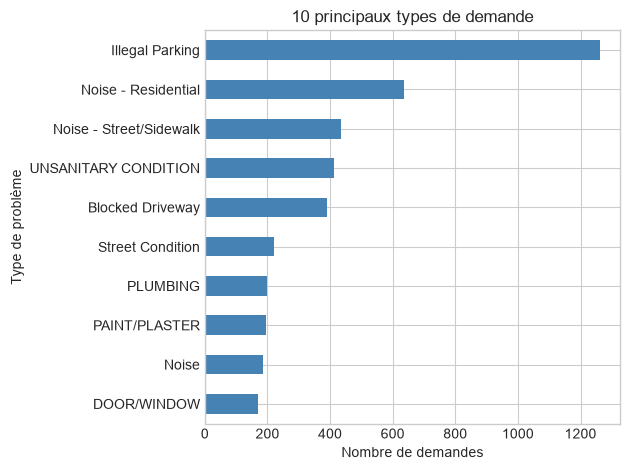

Interprétation : ce classement décrit les types les plus fréquents dans l’échantillon, non leur prévalence dans toute la ville.


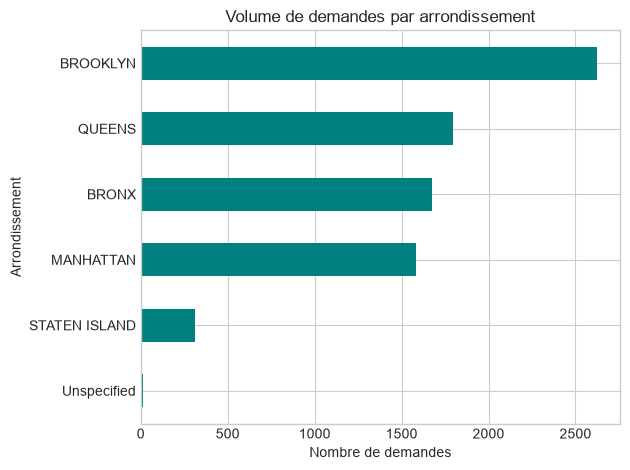

Interprétation : les écarts reflètent les volumes observés et peuvent aussi dépendre de la couverture de l’extrait.


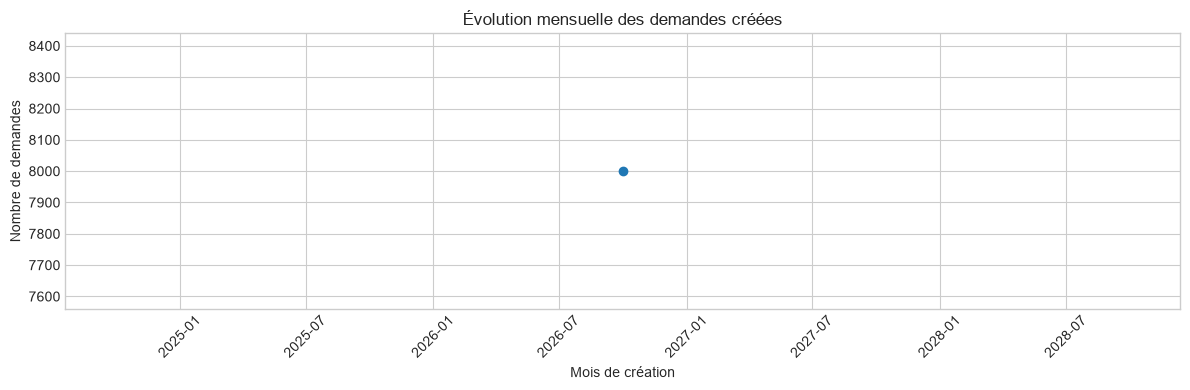

Interprétation : les derniers mois peuvent être incomplets et l’extrait peut être limité dans le temps.


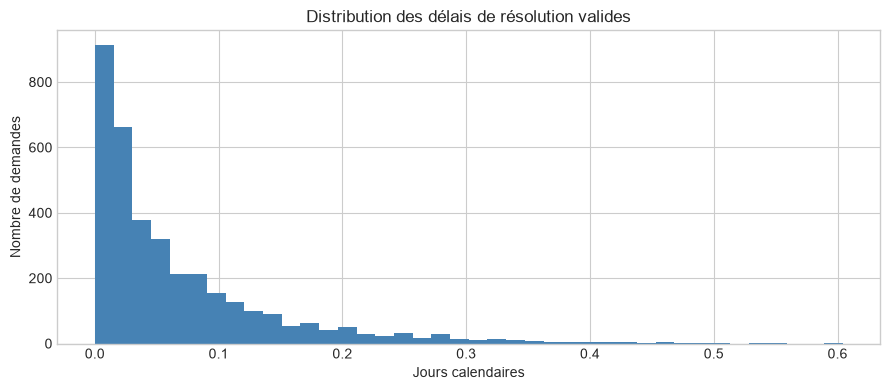

Interprétation : la distribution est limitée aux demandes fermées calculables ; inspecter les valeurs extrêmes.


In [13]:
if kpi_by_complaint_type is not None:
    plot = kpi_by_complaint_type.head(10).sort_values("request_count")
    ax = plot.plot.barh(x="complaint_type", y="request_count", color="steelblue", legend=False)
    ax.set(title="10 principaux types de demande", xlabel="Nombre de demandes", ylabel="Type de problème")
    plt.tight_layout(); plt.show()
    print("Interprétation : ce classement décrit les types les plus fréquents dans l’échantillon, non leur prévalence dans toute la ville.")
if kpi_by_borough is not None:
    plot = kpi_by_borough.sort_values("request_count")
    ax = plot.plot.barh(x="borough", y="request_count", color="teal", legend=False)
    ax.set(title="Volume de demandes par arrondissement", xlabel="Nombre de demandes", ylabel="Arrondissement")
    plt.tight_layout(); plt.show()
    print("Interprétation : les écarts reflètent les volumes observés et peuvent aussi dépendre de la couverture de l’extrait.")
if kpi_monthly is not None:
    monthly = kpi_monthly.copy(); monthly["month"] = pd.PeriodIndex(monthly["created_month"], freq="M").to_timestamp()
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(monthly["month"], monthly["request_count"], marker="o")
    ax.set(title="Évolution mensuelle des demandes créées", xlabel="Mois de création", ylabel="Nombre de demandes")
    plt.xticks(rotation=45); plt.tight_layout(); plt.show()
    print("Interprétation : les derniers mois peuvent être incomplets et l’extrait peut être limité dans le temps.")
if valid_resolution.size:
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.hist(valid_resolution, bins=40, color="steelblue")
    ax.set(title="Distribution des délais de résolution valides", xlabel="Jours calendaires", ylabel="Nombre de demandes")
    plt.tight_layout(); plt.show()
    print("Interprétation : la distribution est limitée aux demandes fermées calculables ; inspecter les valeurs extrêmes.")
else:
    print("Distribution non affichée : aucun délai valide.")

## 11. Exports et contrôles de cohérence

Les exports sont placés dans `data/processed/`. Les tables dimensionnelles et mensuelles ne sont créées que si leur colonne nécessaire existe ; les fichiers exportés servent à alimenter des analyses ultérieures. Les contrôles ci-dessous vérifient que les exports relus concordent avec les DataFrames calculés.

In [14]:
kpi_summary_path = processed_dir / "kpi_summary.csv"
kpi_catalog_path = processed_dir / "kpi_catalog.csv"
kpi_summary.to_csv(kpi_summary_path, index=False)
kpi_catalog.to_csv(kpi_catalog_path, index=False)
exports = {"kpi_by_complaint_type.csv": kpi_by_complaint_type,
           "kpi_by_borough.csv": kpi_by_borough,
           "kpi_monthly.csv": kpi_monthly}
exported_paths = [clean_path, kpi_summary_path, kpi_catalog_path]
for filename, table in exports.items():
    if table is not None:
        path = processed_dir / filename
        table.to_csv(path, index=False)
        exported_paths.append(path)

assert len(pd.read_csv(clean_path, low_memory=False)) == len(df_clean)
summary_roundtrip = pd.read_csv(kpi_summary_path)
assert summary_roundtrip["kpi_name"].tolist() == kpi_summary["kpi_name"].tolist()
assert len(pd.read_csv(kpi_catalog_path)) == len(kpi_catalog)
for filename, table in exports.items():
    if table is not None:
        assert len(pd.read_csv(processed_dir / filename)) == len(table)
print("Exports vérifiés :")
for path in exported_paths:
    print(f"- {path} ({path.stat().st_size:,} octets)")
print("Population fermeture : dénominateur = demandes dont created_date est valide ; numérateur = celles dont closed_date est valide.")

Exports vérifiés :
- d:\Analyst_Agent\data\processed\nyc311_clean.csv (6,257,516 octets)
- d:\Analyst_Agent\data\processed\kpi_summary.csv (411 octets)
- d:\Analyst_Agent\data\processed\kpi_catalog.csv (1,495 octets)
- d:\Analyst_Agent\data\processed\kpi_by_complaint_type.csv (2,867 octets)
- d:\Analyst_Agent\data\processed\kpi_by_borough.csv (114 octets)
- d:\Analyst_Agent\data\processed\kpi_monthly.csv (43 octets)
Population fermeture : dénominateur = demandes dont created_date est valide ; numérateur = celles dont closed_date est valide.


## 12. Limites et prochaines étapes

### Résumé du prototype

- **Nettoyage :** noms standardisés avec correspondance source, espaces retirés, chaînes vides converties en manquantes, dates parsées, répétitions exactes et clés répétées traitées selon la règle documentée. Le CSV brut n’est pas modifié.
- **KPI :** volume, délai moyen et médian, taux de fermeture, volumes par type/borough/agency, évolution mensuelle et médianes de délai par groupes lorsque les champs sont disponibles.
- **Qualité restante :** les valeurs manquantes, dates invalides et incohérences sont rapportées ; aucune valeur inconnue n’est inventée. Les groupes avec petits effectifs demandent de la prudence.
- **À valider avec l’équipe :** sémantique des répétitions `unique_key`, seuil de durée suspecte, définition métier de fermeture et période d’observation. Le seuil de dix ans est un contrôle exploratoire, pas un SLA.
- **Transmission à l’Agent BI Analyst :** fournir `kpi_summary.csv`, les tables de ventilation, `kpi_catalog.csv` et les métadonnées de population/limites. L’agent interprétera ces résultats déterministes plutôt que de recalculer les chiffres.

Ce notebook analyse uniquement le CSV local : les résultats n’ont de portée que sur cet extrait et ne décrivent pas automatiquement l’ensemble des demandes NYC 311.